#Loads the libraries and the CSV

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

DATA_PATH = "Dataset.csv"
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()

Shape: (9551, 21)


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


#Counts missing values and duplicates, counts rating 0, plots two histograms

Missing values:
Cuisines    9
dtype: int64

Duplicate rows: 0

Restaurants with rating 0 (unrated): 2148 (22.5%)


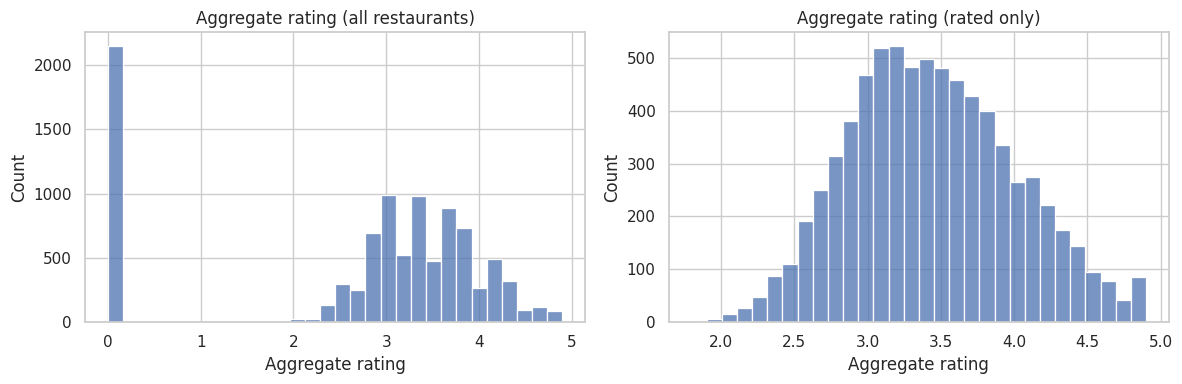

In [ ]:
print("Missing values:")
print(df.isna().sum()[df.isna().sum() > 0])
print("\nDuplicate rows:", df.duplicated().sum())

zero_ratings = (df["Aggregate rating"] == 0).sum()
print(f"\nRestaurants with rating 0 (unrated): {zero_ratings} ({zero_ratings / len(df):.1%})")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["Aggregate rating"], bins=30, ax=ax[0])
ax[0].set_title("Aggregate rating (all restaurants)")
sns.histplot(df.loc[df["Aggregate rating"] > 0, "Aggregate rating"], bins=30, ax=ax[1])
ax[1].set_title("Aggregate rating (rated only)")
plt.tight_layout()
plt.show()

# Removes duplicates, fills missing cuisines with “Unknown”, creates primary_cuisine (the first cuisine listed)

In [ ]:
df = df.drop_duplicates().copy()
df["Cuisines"] = df["Cuisines"].fillna("Unknown")

# primary cuisine = first cuisine listed
df["primary_cuisine"] = df["Cuisines"].str.split(",").str[0].str.strip()

print("Cleaned shape:", df.shape)

Cleaned shape: (9551, 22)


#Turns Yes/No into 1/0, counts cuisines, keeps the top 10 cities and cuisines (rest “Other”), then one-hot encodes


In [ ]:
def top_n_or_other(series, n):
    """Keep the n most common values, replace the rest with 'Other'."""
    top = series.value_counts().head(n).index
    return series.where(series.isin(top), "Other")

features = pd.DataFrame({
    "votes": df["Votes"],
    "price_range": df["Price range"],
    "has_table_booking": (df["Has Table booking"] == "Yes").astype(int),
    "has_online_delivery": (df["Has Online delivery"] == "Yes").astype(int),
    "is_delivering_now": (df["Is delivering now"] == "Yes").astype(int),
    "num_cuisines": df["Cuisines"].str.split(",").apply(len),
    "country": df["Country Code"].astype(str),
    "city": top_n_or_other(df["City"], 10),
    "primary_cuisine": top_n_or_other(df["primary_cuisine"], 10),
})

features = pd.get_dummies(features, columns=["country", "city", "primary_cuisine"], drop_first=True)
features["rating"] = df["Aggregate rating"].values

print("Final feature table:", features.shape)
features.head()

Final feature table: (9551, 41)


,votes,price_range,has_table_booking,has_online_delivery,is_delivering_now,num_cuisines,country_14,country_148,country_162,country_166,...,primary_cuisine_Cafe,primary_cuisine_Chinese,primary_cuisine_Continental,primary_cuisine_Fast Food,primary_cuisine_Mithai,primary_cuisine_North Indian,primary_cuisine_Other,primary_cuisine_South Indian,primary_cuisine_Street Food,rating
0,314,3,1,0,0,3,False,False,True,False,...,False,False,False,False,False,False,True,False,False,4.8
1,591,3,1,0,0,1,False,False,True,False,...,False,False,False,False,False,False,True,False,False,4.5
2,270,4,1,0,0,4,False,False,True,False,...,False,False,False,False,False,False,True,False,False,4.4
3,365,4,0,0,0,2,False,False,True,False,...,False,False,False,False,False,False,True,False,False,4.9
4,229,4,1,0,0,2,False,False,True,False,...,False,False,False,False,False,False,True,False,False,4.8


# Splits 80/20, trains Linear Regression, Decision Tree and Random Forest, and reports MSE, RMSE and R² on the unseen 20%


In [ ]:
def run_experiment(data, label):
    X = data.drop(columns="rating")
    y = data["rating"]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    models = {
        "Linear Regression": LinearRegression(),
        "Decision Tree": DecisionTreeRegressor(max_depth=5, random_state=42),
        "Random Forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=2,
                                               random_state=42, n_jobs=-1),
    }

    rows, fitted = [], {}
    for name, model in models.items():
        model.fit(X_train, y_train)
        pred = model.predict(X_test)
        mse = mean_squared_error(y_test, pred)
        rows.append({"dataset": label, "model": name,
                     "MSE": mse, "RMSE": np.sqrt(mse), "R2": r2_score(y_test, pred)})
        fitted[name] = model
    return pd.DataFrame(rows), fitted, X_train, X_test, y_test

#Runs it once with all restaurants, once with rated ones only

In [ ]:
# Experiment A: ALL restaurants (including unrated = 0)
res_all, models_all, *_ = run_experiment(features, "All (with zeros)")

# Experiment B: only RATED restaurants (rating > 0)
rated = features[features["rating"] > 0]
res_rated, models_rated, X_train_r, X_test_r, y_test_r = run_experiment(rated, "Rated only")

results = pd.concat([res_all, res_rated], ignore_index=True)
results.round(3)

,dataset,model,MSE,RMSE,R2
0,All (with zeros),Linear Regression,1.459,1.208,0.359
1,All (with zeros),Decision Tree,0.105,0.325,0.954
2,All (with zeros),Random Forest,0.105,0.324,0.954
3,Rated only,Linear Regression,0.156,0.395,0.495
4,Rated only,Decision Tree,0.133,0.365,0.570
5,Rated only,Random Forest,0.127,0.356,0.590


# Scatter of true vs predicted ratings with a perfect-prediction line

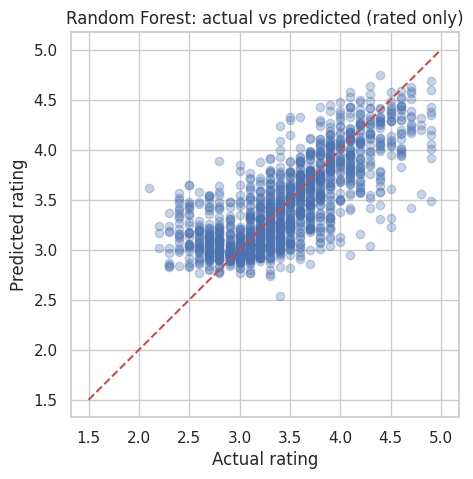

In [ ]:
best = models_rated["Random Forest"]
pred = best.predict(X_test_r)

plt.figure(figsize=(5, 5))
plt.scatter(y_test_r, pred, alpha=0.3)
plt.plot([1.5, 5], [1.5, 5], "r--")
plt.xlabel("Actual rating")
plt.ylabel("Predicted rating")
plt.title("Random Forest: actual vs predicted (rated only)")
plt.show()

#Ranks which features the Random Forest used most

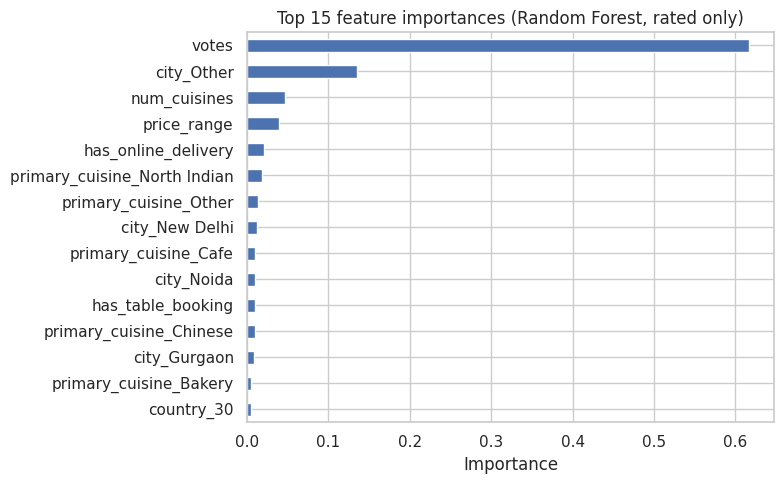

,0
votes,0.617
city_Other,0.135
num_cuisines,0.047
price_range,0.039
has_online_delivery,0.021
primary_cuisine_North Indian,0.018
primary_cuisine_Other,0.013
city_New Delhi,0.012
primary_cuisine_Cafe,0.010
city_Noida,0.010


In [ ]:
importances = pd.Series(best.feature_importances_, index=X_train_r.columns).sort_values(ascending=False)

plt.figure(figsize=(8, 5))
importances.head(15).sort_values().plot(kind="barh")
plt.title("Top 15 feature importances (Random Forest, rated only)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

importances.head(10).round(3)

# **Conclusion**

#**Best model:** On rated restaurants, the Random Forest performed best with an R² of 0.59 and an RMSE of 0.36, meaning its predictions are off by about a third of a rating point on average. Linear Regression reached 0.495 and the Decision Tree 0.57.

#**Unrated restaurants:** When restaurants with rating 0 were included, R² rose to 0.95. This is misleading: unrated restaurants mostly have zero votes, so the models simply learn that zero votes means rating 0. The rated-only result is the honest measure of performance.

#**Parameter change:** Earlier I changed the Decision Tree max_depth from 8 to 5. R² on rated restaurants dropped slightly from 0.578 to 0.570, suggesting the shallower tree underfits a little. The difference is small and comes from a single train/test split.

#**Important features:** Votes was by far the most important feature (importance 0.617), followed by whether the restaurant is in a smaller city outside the top 10 (0.135), the number of cuisines (0.047) and price range (0.039). This is correlation, not proof that votes cause higher ratings, since good restaurants also attract more votes.

#**Limitations and next steps:** About 91% of the data is from India, so the model may not generalise to other countries. I would try gradient boosting and cross-validation.